# 01 · The house without flexible assets

A house in Porto over a day and a half at 15-minute resolution: a 5 kWp PV array, a four-person household,
a 6.9 kVA grid connection with the Portuguese bi-hourly tariff and no export remuneration.

With nothing to decide, the optimizer only writes the energy balance: whatever PV does not cover is
imported, whatever the house does not use is exported. The resulting cost is the **reference** that the
battery and EV notebooks try to beat.

In [1]:
import sys
from pathlib import Path

# make the package importable without installing it (the notebooks live one level below the repo root)
src = Path().resolve().parent / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

import pandas as pd
pd.set_option("display.precision", 3)

In [2]:
from fennec.examples import baseline
from fennec.utils import describe, energy_balance, plot_dispatch, plot_profiles

home = baseline()
describe(home)

,kind,import_tariff,export_tariff,contracted_power_kw,total_kwh
asset,,,,,
grid,grid,import-bi-daily,export-none,6.9,NaN
pv,pv,NaN,NaN,NaN,45.8
house,load,NaN,NaN,NaN,86.5


## Inputs

`PVProduction` and `Load` are *fixed profiles*: one kWh value per step, produced here by the simple simulators
in `fennec.simulators` (clear-sky solar geometry and an occupancy-based load).

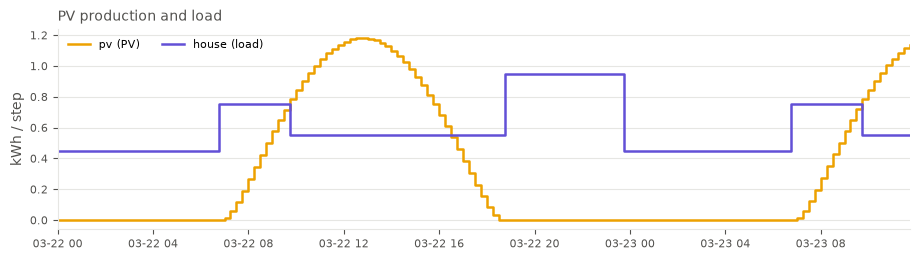

In [3]:
results = home.solve()
plot_profiles(results);

## Result

`SmartHome.solve()` returns a `Results` object: status, objective, and one table of time series per asset.
`summary()` gives the headline numbers and `energy_balance()` the totals exchanged by every asset.

In [4]:
results.summary()

{'status': 'optimal',
 'objective': 7.765792030683107,
 'gap': 0.0,
 'solve_seconds': 0.01,
 'steps': 144,
 'grid_import_kwh': 56.75878078174596,
 'grid_export_kwh': 16.05872602751188,
 'grid_cost': 7.76579203068311}

In [5]:
energy_balance(results)

,kind,to_house_kwh,from_house_kwh,cost
asset,,,,
grid,grid,56.759,16.059,7.766
pv,pv,45.800,0.000,0.000
house,load,0.000,86.500,0.000


The dispatch figure stacks one panel per piece of the house on a shared time axis. Without a battery, the
midday PV surplus is exported for nothing and the evening peak is fully imported at the expensive rate.

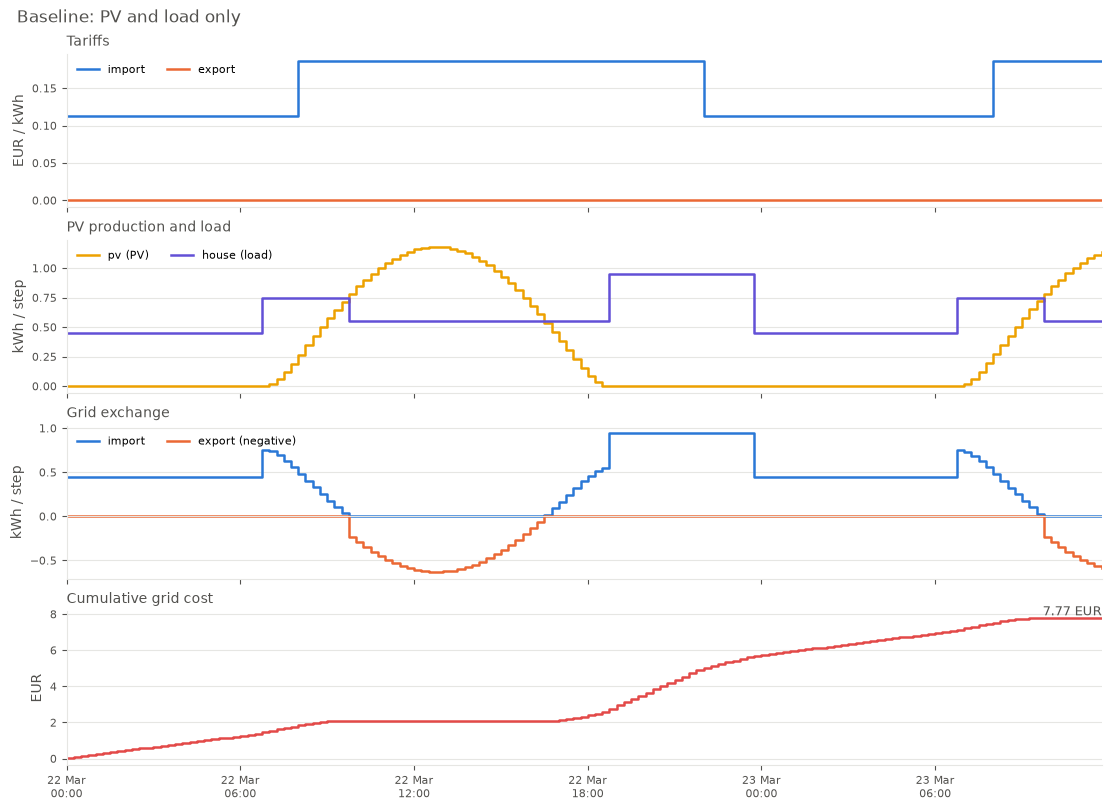

In [6]:
plot_dispatch(results, title="Baseline: PV and load only");

## Working with the time series

`results.frame()` returns a time-indexed `pandas.DataFrame` with `"<asset>.<column>"` columns;
`results.frame("grid")` returns only the grid's columns.

In [7]:
results.frame("grid").head(8)

,energy_from,energy_to,cost,import_price,export_price
time,,,,,
2025-03-22 00:00:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 00:15:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 00:30:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 00:45:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 01:00:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 01:15:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 01:30:00+00:00,0.45,0.0,0.051,0.113,0.0
2025-03-22 01:45:00+00:00,0.45,0.0,0.051,0.113,0.0
